In [229]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [230]:
df = pd.read_csv('bq-results-20251021-151536-1761059869369.csv', dtype_backend='pyarrow')
df.drop(columns=['data_file_year','data_file_month'], inplace=True)

## Filter to Standard Metered Fare Only (rate_code == 1)

Based on analysis in `trip_type_rate_analysis.ipynb`, we filter to only keep standard metered fare trips (rate_code == 1) to eliminate unpredictable trips like airport flat fares, negotiated fares, etc.

- Standard rate (metered fare)
- JFK (flat fare to/from JFK Airport)
- Newark (flat fare to/from Newark Airport)
- Nassau or Westchester (negotiated fare)
- Negotiated fare (other)
- Group ride

In [231]:
rate_counts = df['rate_code'].value_counts().sort_index()
print("\nCount by rate_code:")
print(rate_counts)
print("\nPercentage:")
print((rate_counts / len(df) * 100).round(2))


# Filter to only rate_code == 1
initial_count = len(df)
df = df[df['rate_code'] == 1].copy()
removed_count = initial_count - len(df)
removed_pct = (removed_count / initial_count) * 100

print(f"\nFiltered dataset to rate_code == 1.\nRemoved {removed_count} records ({removed_pct:.2f}%).\nRemaining records: {len(df)}.")


Count by rate_code:
rate_code
1.0     623507
2.0       1784
3.0        312
4.0        643
5.0      26700
6.0          6
99.0        15
Name: count, dtype: int64[pyarrow]

Percentage:
rate_code
1.0     58.53
2.0      0.17
3.0      0.03
4.0      0.06
5.0      2.51
6.0       0.0
99.0      0.0
Name: count, dtype: double[pyarrow]

Filtered dataset to rate_code == 1.
Removed 441843 records (41.47%).
Remaining records: 623507.


In [232]:
taxi_zone_lookup_df = pd.read_csv('taxi_zone_lookup.csv', dtype_backend='pyarrow')
taxi_zone_lookup_df.head()

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [233]:
# Merge for dropoff location
df = df.merge(taxi_zone_lookup_df, left_on='dropoff_location_id', right_on='LocationID', how='left')
df.rename(columns={'Borough': 'dropoff_borough', 'Zone': 'dropoff_zone'}, inplace=True)
df.drop(columns=['LocationID', 'service_zone'], inplace=True)

# Merge for pickup location
df = df.merge(taxi_zone_lookup_df, left_on='pickup_location_id', right_on='LocationID', how='left')
df.rename(columns={'Borough': 'pickup_borough', 'Zone': 'pickup_zone'}, inplace=True)
df.drop(columns=['LocationID', 'service_zone'], inplace=True)

df.head()

,vendor_id,pickup_datetime,dropoff_datetime,store_and_fwd_flag,rate_code,passenger_count,trip_distance,fare_amount,extra,mta_tax,...,distance_between_service,time_between_service,trip_type,imp_surcharge,pickup_location_id,dropoff_location_id,dropoff_borough,dropoff_zone,pickup_borough,pickup_zone
0,2,2021-11-02 10:09:45+00:00,2021-11-02 10:12:11+00:00,N,1.0,1,0.0,0.0,0.0,0.0,...,None,None,1.0,0.0,193,193,Queens,Queensbridge/Ravenswood,Queens,Queensbridge/Ravenswood
1,2,2021-11-02 13:33:59+00:00,2021-11-02 13:34:09+00:00,N,1.0,1,0.0,0.0,0.0,0.0,...,None,None,1.0,0.0,193,193,Queens,Queensbridge/Ravenswood,Queens,Queensbridge/Ravenswood
2,2,2021-11-04 12:33:27+00:00,2021-11-04 12:33:43+00:00,N,1.0,1,0.0,0.0,0.0,0.0,...,None,None,1.0,0.0,193,7,Queens,Astoria,Queens,Queensbridge/Ravenswood
3,2,2021-11-09 16:29:13+00:00,2021-11-09 16:29:53+00:00,N,1.0,1,0.0,0.0,0.0,0.0,...,None,None,1.0,0.0,264,264,Unknown,<NA>,Unknown,<NA>
4,2,2021-11-09 16:40:59+00:00,2021-11-09 16:41:10+00:00,N,1.0,1,0.0,0.0,0.0,0.0,...,None,None,1.0,0.0,193,193,Queens,Queensbridge/Ravenswood,Queens,Queensbridge/Ravenswood


In [234]:
df.drop(columns=['dropoff_location_id', 'pickup_location_id'], inplace=True)

In [235]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 623507 entries, 0 to 623506
Data columns (total 24 columns):
 #   Column                    Non-Null Count   Dtype          
---  ------                    --------------   -----          
 0   vendor_id                 623507 non-null  int64[pyarrow] 
 1   pickup_datetime           623507 non-null  string[pyarrow]
 2   dropoff_datetime          623507 non-null  string[pyarrow]
 3   store_and_fwd_flag        623507 non-null  string[pyarrow]
 4   rate_code                 623507 non-null  double[pyarrow]
 5   passenger_count           623507 non-null  int64[pyarrow] 
 6   trip_distance             623507 non-null  double[pyarrow]
 7   fare_amount               623507 non-null  double[pyarrow]
 8   extra                     623507 non-null  double[pyarrow]
 9   mta_tax                   623507 non-null  double[pyarrow]
 10  tip_amount                623507 non-null  double[pyarrow]
 11  tolls_amount              623507 non-null  double[py

In [236]:
#drop columns with all null values
df = df.dropna(axis=1, how='all')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 623507 entries, 0 to 623506
Data columns (total 20 columns):
 #   Column              Non-Null Count   Dtype          
---  ------              --------------   -----          
 0   vendor_id           623507 non-null  int64[pyarrow] 
 1   pickup_datetime     623507 non-null  string[pyarrow]
 2   dropoff_datetime    623507 non-null  string[pyarrow]
 3   store_and_fwd_flag  623507 non-null  string[pyarrow]
 4   rate_code           623507 non-null  double[pyarrow]
 5   passenger_count     623507 non-null  int64[pyarrow] 
 6   trip_distance       623507 non-null  double[pyarrow]
 7   fare_amount         623507 non-null  double[pyarrow]
 8   extra               623507 non-null  double[pyarrow]
 9   mta_tax             623507 non-null  double[pyarrow]
 10  tip_amount          623507 non-null  double[pyarrow]
 11  tolls_amount        623507 non-null  double[pyarrow]
 12  total_amount        623507 non-null  double[pyarrow]
 13  payment_type  

In [237]:
df.pickup_datetime = pd.to_datetime(df.pickup_datetime)
df.dropoff_datetime = pd.to_datetime(df.dropoff_datetime)

In [238]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 623507 entries, 0 to 623506
Data columns (total 20 columns):
 #   Column              Non-Null Count   Dtype              
---  ------              --------------   -----              
 0   vendor_id           623507 non-null  int64[pyarrow]     
 1   pickup_datetime     623507 non-null  datetime64[ns, UTC]
 2   dropoff_datetime    623507 non-null  datetime64[ns, UTC]
 3   store_and_fwd_flag  623507 non-null  string[pyarrow]    
 4   rate_code           623507 non-null  double[pyarrow]    
 5   passenger_count     623507 non-null  int64[pyarrow]     
 6   trip_distance       623507 non-null  double[pyarrow]    
 7   fare_amount         623507 non-null  double[pyarrow]    
 8   extra               623507 non-null  double[pyarrow]    
 9   mta_tax             623507 non-null  double[pyarrow]    
 10  tip_amount          623507 non-null  double[pyarrow]    
 11  tolls_amount        623507 non-null  double[pyarrow]    
 12  total_amount    

In [239]:
df.head()

,vendor_id,pickup_datetime,dropoff_datetime,store_and_fwd_flag,rate_code,passenger_count,trip_distance,fare_amount,extra,mta_tax,tip_amount,tolls_amount,total_amount,payment_type,trip_type,imp_surcharge,dropoff_borough,dropoff_zone,pickup_borough,pickup_zone
0,2,2021-11-02 10:09:45+00:00,2021-11-02 10:12:11+00:00,N,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,Queens,Queensbridge/Ravenswood,Queens,Queensbridge/Ravenswood
1,2,2021-11-02 13:33:59+00:00,2021-11-02 13:34:09+00:00,N,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,Queens,Queensbridge/Ravenswood,Queens,Queensbridge/Ravenswood
2,2,2021-11-04 12:33:27+00:00,2021-11-04 12:33:43+00:00,N,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,Queens,Astoria,Queens,Queensbridge/Ravenswood
3,2,2021-11-09 16:29:13+00:00,2021-11-09 16:29:53+00:00,N,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,Unknown,<NA>,Unknown,<NA>
4,2,2021-11-09 16:40:59+00:00,2021-11-09 16:41:10+00:00,N,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,Queens,Queensbridge/Ravenswood,Queens,Queensbridge/Ravenswood


In [240]:
df['trip_duration (min)'] = (df.dropoff_datetime - df.pickup_datetime).dt.total_seconds() / 60

In [241]:
df.drop(columns=['dropoff_datetime'], inplace=True)

In [242]:
df.head()

,vendor_id,pickup_datetime,store_and_fwd_flag,rate_code,passenger_count,trip_distance,fare_amount,extra,mta_tax,tip_amount,tolls_amount,total_amount,payment_type,trip_type,imp_surcharge,dropoff_borough,dropoff_zone,pickup_borough,pickup_zone,trip_duration (min)
0,2,2021-11-02 10:09:45+00:00,N,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,Queens,Queensbridge/Ravenswood,Queens,Queensbridge/Ravenswood,2.433333
1,2,2021-11-02 13:33:59+00:00,N,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,Queens,Queensbridge/Ravenswood,Queens,Queensbridge/Ravenswood,0.166667
2,2,2021-11-04 12:33:27+00:00,N,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,Queens,Astoria,Queens,Queensbridge/Ravenswood,0.266667
3,2,2021-11-09 16:29:13+00:00,N,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,Unknown,<NA>,Unknown,<NA>,0.666667
4,2,2021-11-09 16:40:59+00:00,N,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,Queens,Queensbridge/Ravenswood,Queens,Queensbridge/Ravenswood,0.183333


In [243]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 623507 entries, 0 to 623506
Data columns (total 20 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   vendor_id            623507 non-null  int64[pyarrow]     
 1   pickup_datetime      623507 non-null  datetime64[ns, UTC]
 2   store_and_fwd_flag   623507 non-null  string[pyarrow]    
 3   rate_code            623507 non-null  double[pyarrow]    
 4   passenger_count      623507 non-null  int64[pyarrow]     
 5   trip_distance        623507 non-null  double[pyarrow]    
 6   fare_amount          623507 non-null  double[pyarrow]    
 7   extra                623507 non-null  double[pyarrow]    
 8   mta_tax              623507 non-null  double[pyarrow]    
 9   tip_amount           623507 non-null  double[pyarrow]    
 10  tolls_amount         623507 non-null  double[pyarrow]    
 11  total_amount         623507 non-null  double[pyarrow]    
 12  pa

In [244]:
print(df.dtypes)

vendor_id                   int64[pyarrow]
pickup_datetime        datetime64[ns, UTC]
store_and_fwd_flag         string[pyarrow]
rate_code                  double[pyarrow]
passenger_count             int64[pyarrow]
trip_distance              double[pyarrow]
fare_amount                double[pyarrow]
extra                      double[pyarrow]
mta_tax                    double[pyarrow]
tip_amount                 double[pyarrow]
tolls_amount               double[pyarrow]
total_amount               double[pyarrow]
payment_type               double[pyarrow]
trip_type                  double[pyarrow]
imp_surcharge              double[pyarrow]
dropoff_borough            string[pyarrow]
dropoff_zone               string[pyarrow]
pickup_borough             string[pyarrow]
pickup_zone                string[pyarrow]
trip_duration (min)                float64
dtype: object


<Axes: >

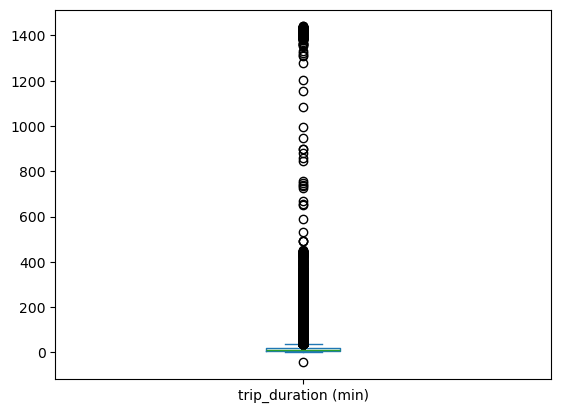

In [245]:
df['trip_duration (min)'].plot(kind='box')

<Axes: >

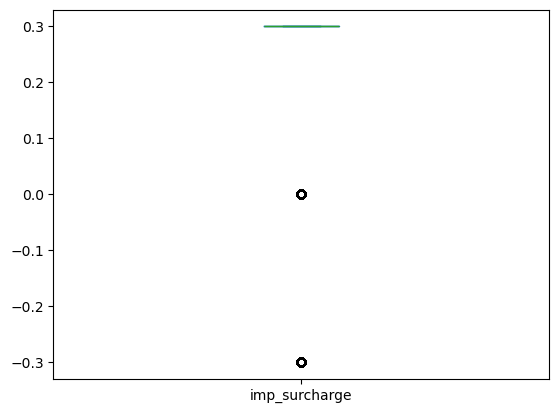

In [246]:
df['imp_surcharge'].plot(kind='box')

<Axes: xlabel='trip_type'>

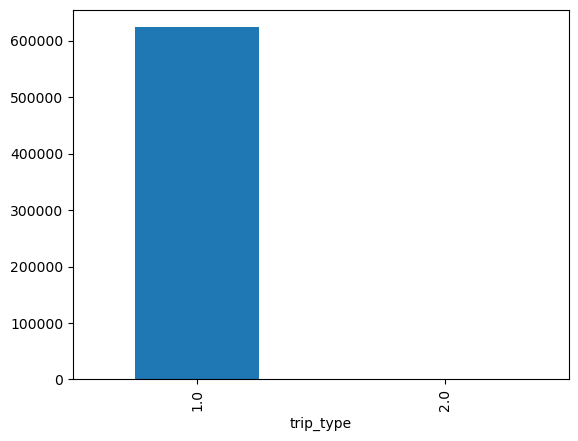

In [247]:
df['trip_type'].value_counts().plot(kind='bar')

<Axes: xlabel='payment_type'>

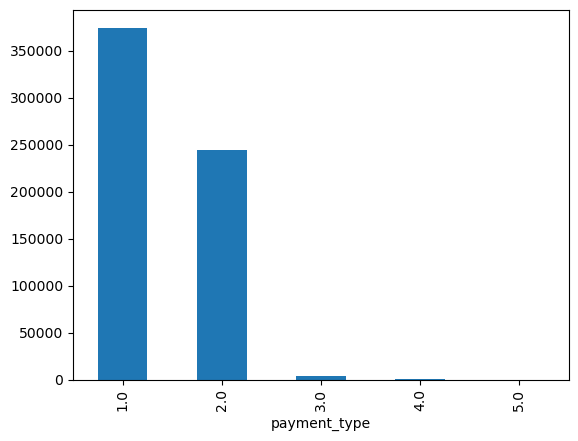

In [248]:
df['payment_type'].value_counts().plot(kind='bar')

<Axes: >

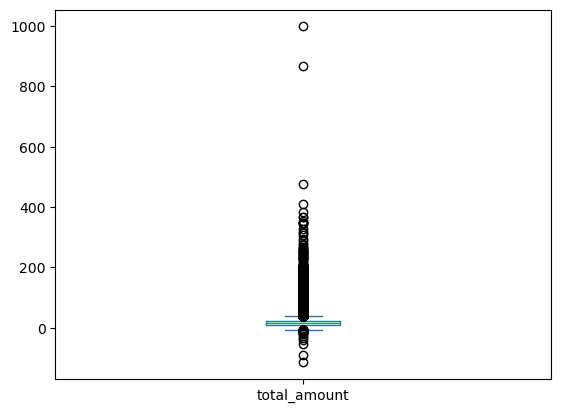

In [249]:
df['total_amount'].plot(kind='box')

<Axes: >

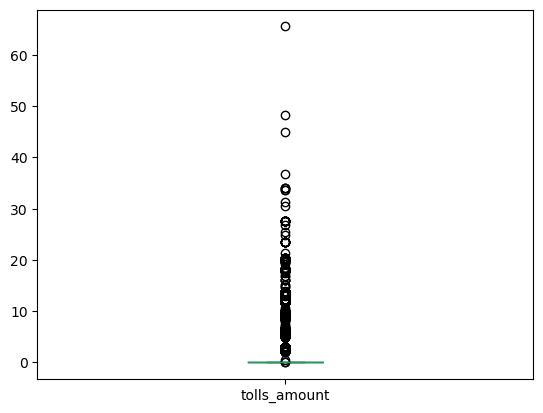

In [250]:
df['tolls_amount'].plot(kind='box')

<Axes: >

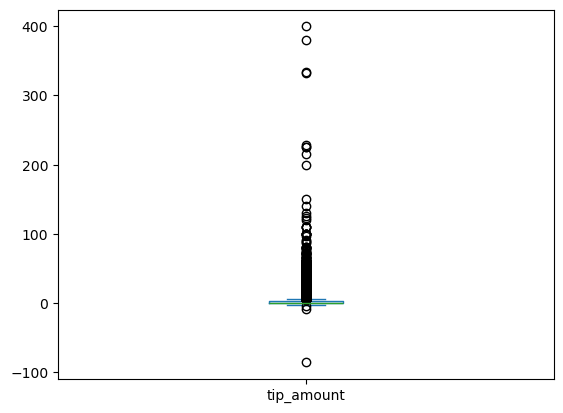

In [251]:
df['tip_amount'].plot(kind='box')

<Axes: >

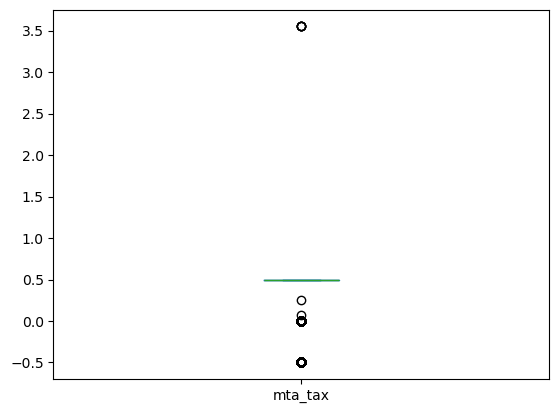

In [252]:
df['mta_tax'].plot(kind='box')

<Axes: >

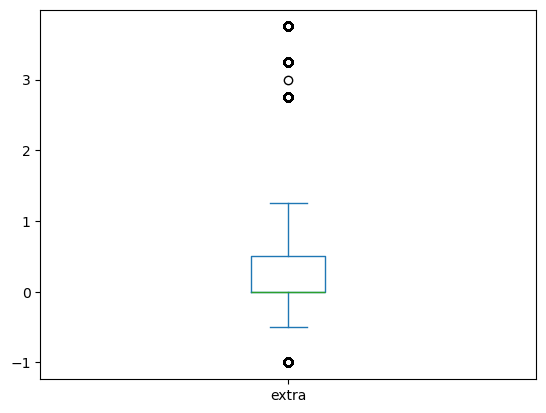

In [253]:
df['extra'].plot(kind='box')

<Axes: >

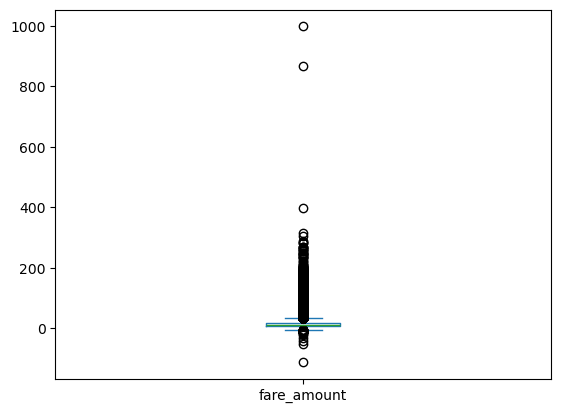

In [254]:
df['fare_amount'].plot(kind='box')

<Axes: >

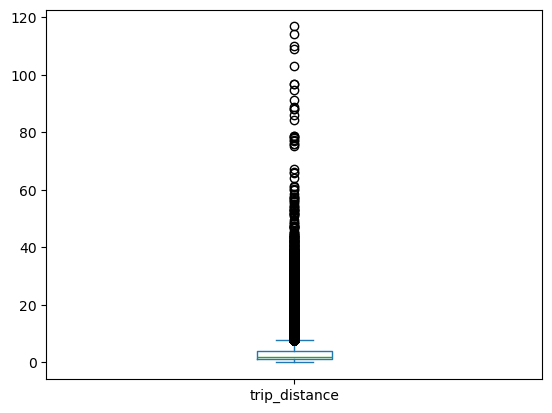

In [255]:
df['trip_distance'].plot(kind='box')

<Axes: >

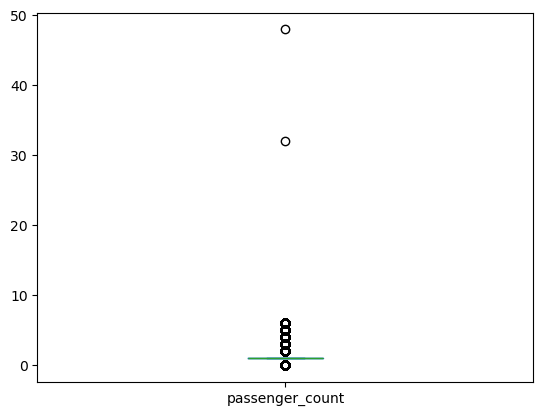

In [256]:
df['passenger_count'].plot(kind='box')

<Axes: xlabel='rate_code'>

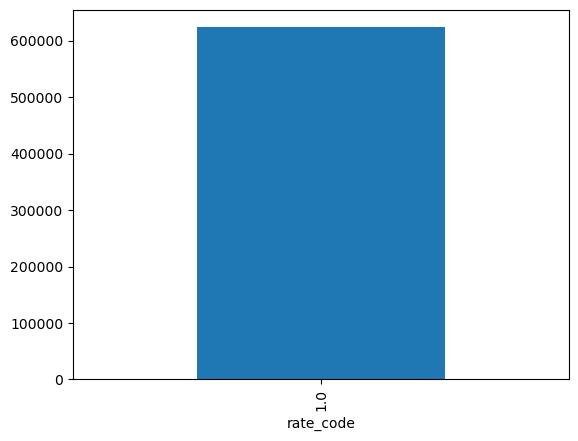

In [257]:
df['rate_code'].value_counts().plot(kind='bar')

<Axes: xlabel='store_and_fwd_flag'>

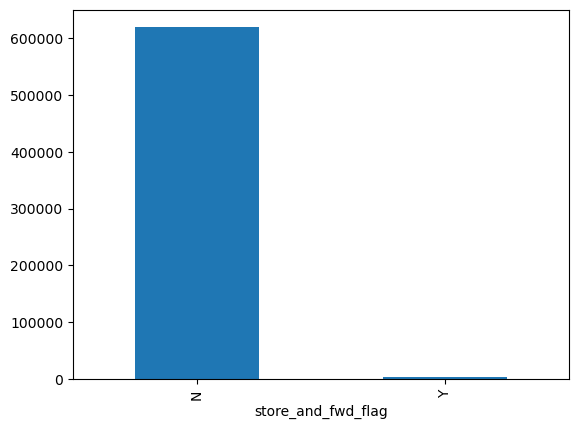

In [258]:
df['store_and_fwd_flag'].value_counts().plot(kind='bar')

<Axes: xlabel='vendor_id'>

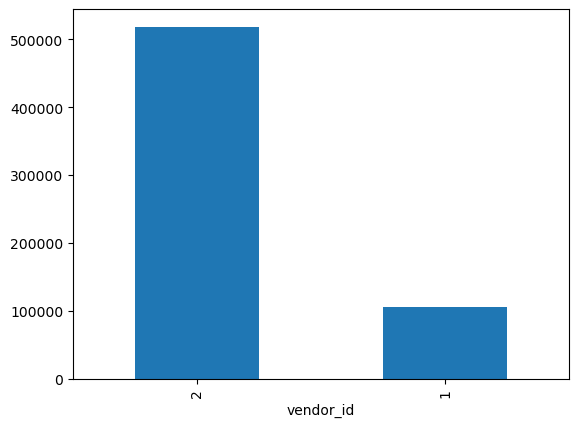

In [259]:
df['vendor_id'].value_counts().plot(kind='bar')

<Axes: xlabel='pickup_borough'>

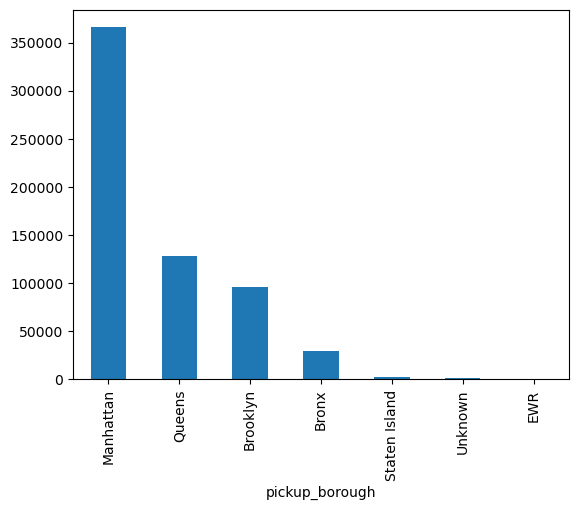

In [260]:
df['pickup_borough'].value_counts().plot(kind='bar')

<Axes: xlabel='dropoff_borough'>

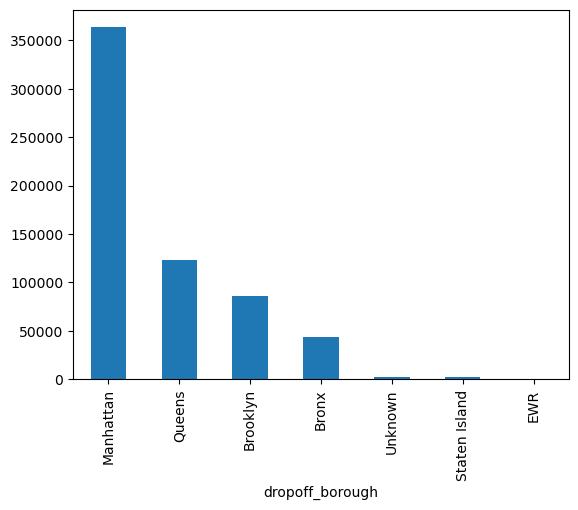

In [261]:
df['dropoff_borough'].value_counts().plot(kind='bar')

<Axes: xlabel='dropoff_zone'>

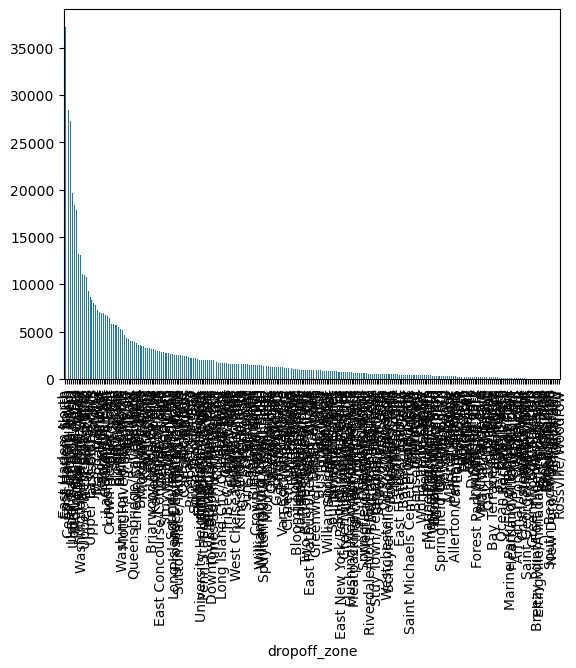

In [262]:
df['dropoff_zone'].value_counts().plot(kind='bar')

<Axes: xlabel='pickup_zone'>

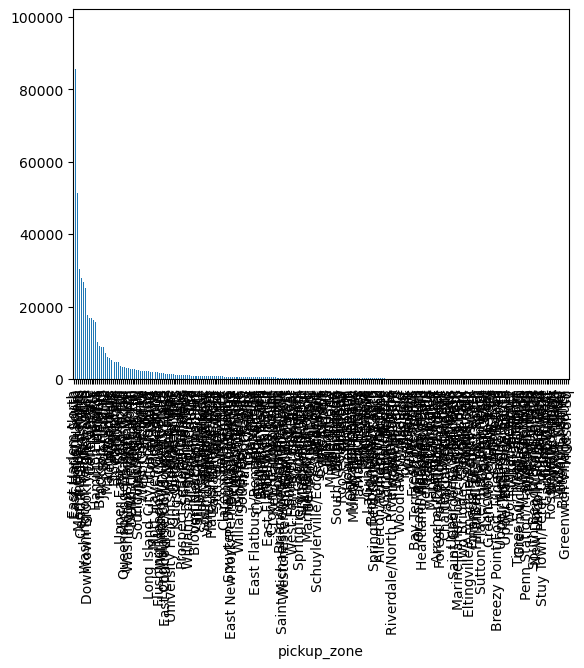

In [263]:
df['pickup_zone'].value_counts().plot(kind='bar')

**Note:**

The NYC TLC taxi zone lookup table provides both the zone name and the service zone (such as 'Yellow Zone', 'Boro Zone', 'Airports', etc.).

Using the zone name directly for feature engineering would result in a very large number of dummy variables, which can harm model performance due to the curse of dimensionality. Instead, using broader categories like the service zone or borough reduces the number of categories and helps prevent this issue, making your model more efficient and less prone to overfitting.

In [264]:
df.drop(columns=['pickup_zone', 'dropoff_zone'], inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 623507 entries, 0 to 623506
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   vendor_id            623507 non-null  int64[pyarrow]     
 1   pickup_datetime      623507 non-null  datetime64[ns, UTC]
 2   store_and_fwd_flag   623507 non-null  string[pyarrow]    
 3   rate_code            623507 non-null  double[pyarrow]    
 4   passenger_count      623507 non-null  int64[pyarrow]     
 5   trip_distance        623507 non-null  double[pyarrow]    
 6   fare_amount          623507 non-null  double[pyarrow]    
 7   extra                623507 non-null  double[pyarrow]    
 8   mta_tax              623507 non-null  double[pyarrow]    
 9   tip_amount           623507 non-null  double[pyarrow]    
 10  tolls_amount         623507 non-null  double[pyarrow]    
 11  total_amount         623507 non-null  double[pyarrow]    
 12  pa

In [265]:
df['rate_code'] = df['rate_code'].astype('category')
df['imp_surcharge'] = df['imp_surcharge'].astype('category')
df['trip_type'] = df['trip_type'].astype('category')
df['payment_type'] = df['payment_type'].astype('category')
df['store_and_fwd_flag'] = df['store_and_fwd_flag'].astype('category')
df['dropoff_borough'] = df['dropoff_borough'].astype('category')
df['pickup_borough'] = df['pickup_borough'].astype('category')

In [266]:
# Make a copy of the dataframe for correlation analysis
df_corr = df.copy()

In [267]:
df_corr = pd.get_dummies(df_corr, columns=['store_and_fwd_flag', 'dropoff_borough', 'pickup_borough','imp_surcharge','trip_type','payment_type', 'rate_code'], drop_first=True)

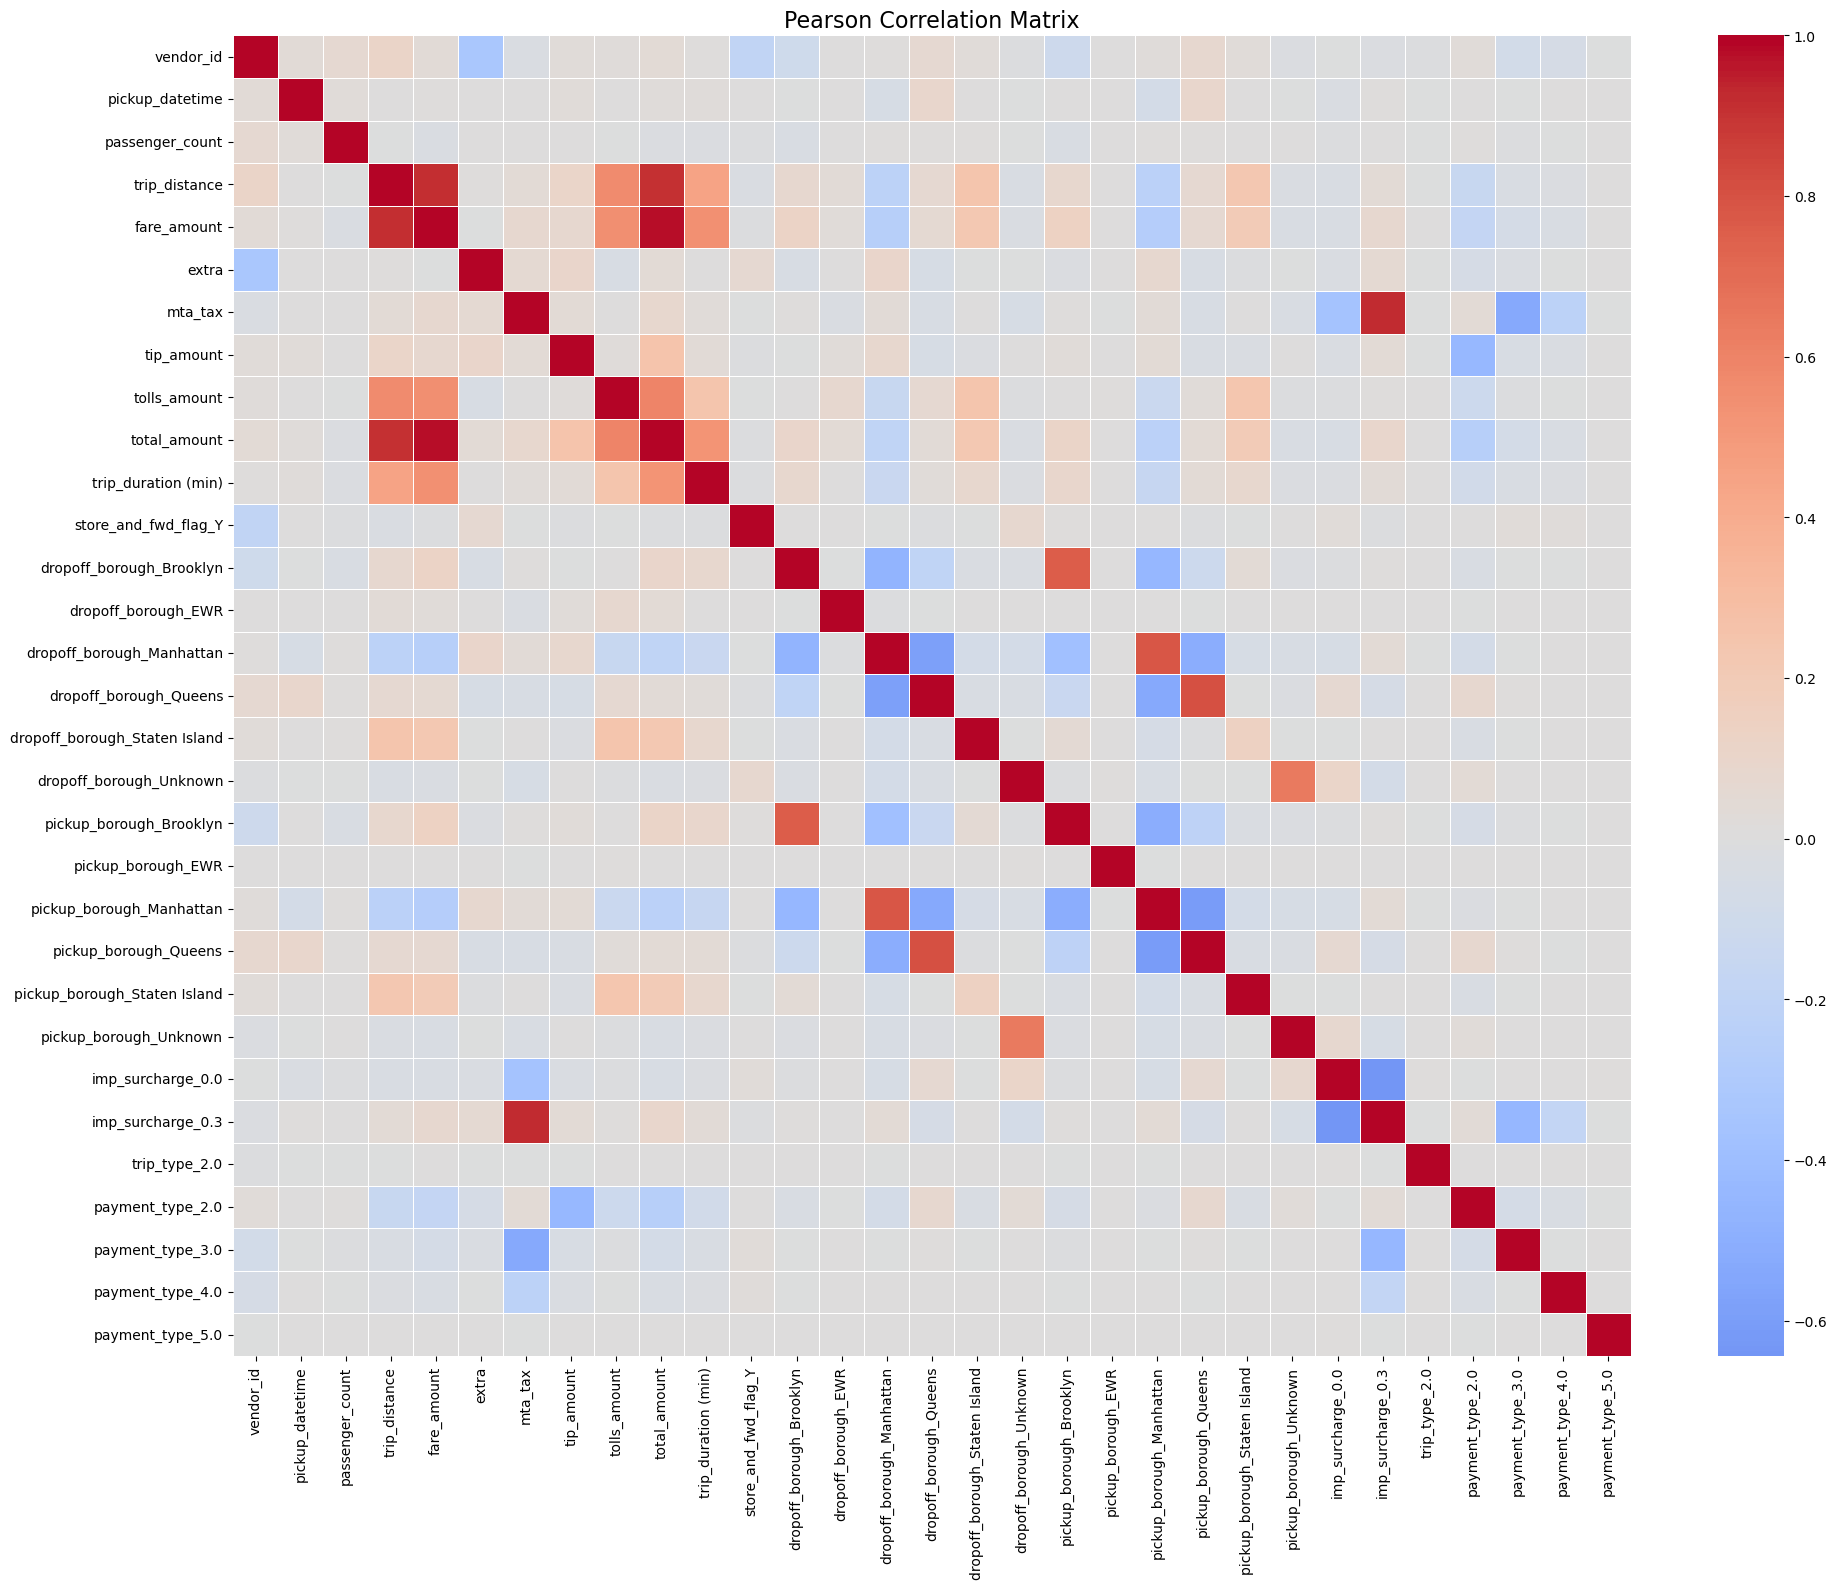

In [268]:
corr_matrix = df_corr.corr(method='pearson')

plt.figure(figsize=(20, 16))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Pearson Correlation Matrix', fontsize=16)
plt.tight_layout()
plt.show()

In [269]:
target = 'trip_duration (min)'

pearson_corr = df_corr.corr(method='pearson')[target].drop(target)
spearman_corr = df_corr.corr(method='spearman')[target].drop(target)

corr_with_target = pd.DataFrame({
    'Pearson': pearson_corr,
    'Spearman': spearman_corr
})

dropped due to high collinearity with other features:

- Group 1: 'total_amount', 'fare_amount', 'trip_distance' -> kept 'trip_distance' due to highest correlation with target

- Group 2: 'mta_tax', 'imp_surcharge' -> kept 'imp_surcharge' due to higher correlation with target

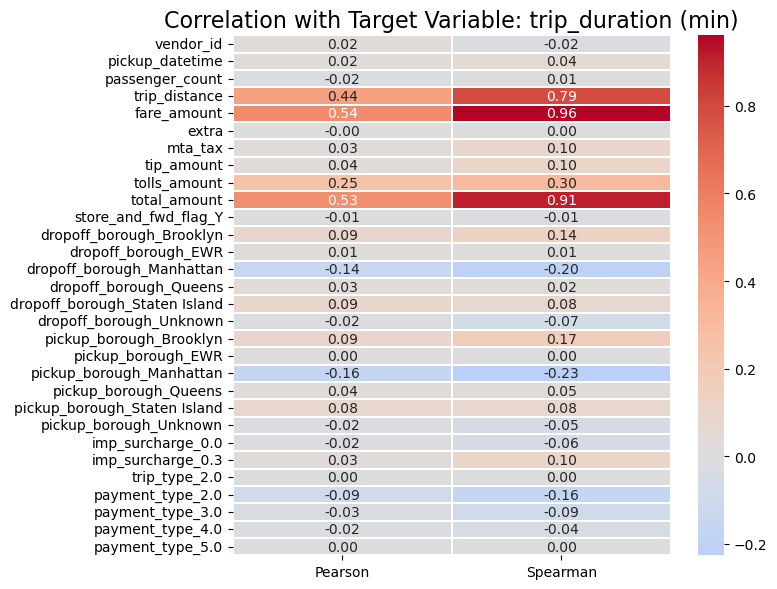

In [270]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_with_target, cmap='coolwarm', center=0, annot=True, cbar=True, linewidths=0.1, fmt=".2f")

plt.title(f'Correlation with Target Variable: {target}', fontsize=16)
plt.tight_layout()
plt.show()

**Correlation Analysis Findings:**

The correlation analysis reveals that there is little to no linear correlation between most features and the target variable (`trip_duration (min)`), as shown by the low Pearson correlation coefficients. However, the Spearman correlation coefficients indicate significant monotonic non-linear relationships between several features and the target.

This suggests that while the relationships are not strictly linear, there are strong monotonic trends where increases in certain features (like `trip_distance` and `total_amount`) correspond to consistent increases or decreases in trip duration. This is important for model selection, as non-linear models (like decision trees, random forests, or neural networks) may capture these relationships more effectively than linear models.

In [271]:
corr_with_target.Pearson = corr_with_target.Pearson.apply(lambda x: np.nan if abs(x) < 0.1 else x)
corr_with_target.Spearman = corr_with_target.Spearman.apply(lambda x: np.nan if abs(x) < 0.1 else x)
high_corr_with_target = corr_with_target.dropna(how='all', inplace=False)
low_corr_with_target = corr_with_target[corr_with_target.isna().all(axis=1)]

In [272]:
display(high_corr_with_target)
display(low_corr_with_target)

,Pearson,Spearman
trip_distance,0.442336,0.791740
fare_amount,0.543451,0.960801
tip_amount,NaN,0.101371
tolls_amount,0.247864,0.304164
total_amount,0.526232,0.912800
dropoff_borough_Brooklyn,NaN,0.141561
dropoff_borough_Manhattan,-0.144277,-0.204358
pickup_borough_Brooklyn,NaN,0.168209
pickup_borough_Manhattan,-0.158484,-0.226082
imp_surcharge_0.3,NaN,0.100185


,Pearson,Spearman
vendor_id,NaN,NaN
pickup_datetime,NaN,NaN
passenger_count,NaN,NaN
extra,NaN,NaN
mta_tax,NaN,NaN
store_and_fwd_flag_Y,NaN,NaN
dropoff_borough_EWR,NaN,NaN
dropoff_borough_Queens,NaN,NaN
dropoff_borough_Staten Island,NaN,NaN
dropoff_borough_Unknown,NaN,NaN


In [273]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 623507 entries, 0 to 623506
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   vendor_id            623507 non-null  int64[pyarrow]     
 1   pickup_datetime      623507 non-null  datetime64[ns, UTC]
 2   store_and_fwd_flag   623507 non-null  category           
 3   rate_code            623507 non-null  category           
 4   passenger_count      623507 non-null  int64[pyarrow]     
 5   trip_distance        623507 non-null  double[pyarrow]    
 6   fare_amount          623507 non-null  double[pyarrow]    
 7   extra                623507 non-null  double[pyarrow]    
 8   mta_tax              623507 non-null  double[pyarrow]    
 9   tip_amount           623507 non-null  double[pyarrow]    
 10  tolls_amount         623507 non-null  double[pyarrow]    
 11  total_amount         623507 non-null  double[pyarrow]    
 12  pa

In [274]:
# Drop the identified columns from the main dataframe
df.drop(columns=['vendor_id', 'pickup_datetime', 'rate_code', 'passenger_count', 'tip_amount', 'trip_type', 'imp_surcharge', 'store_and_fwd_flag','total_amount', 'trip_distance'], inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 623507 entries, 0 to 623506
Data columns (total 8 columns):
 #   Column               Non-Null Count   Dtype          
---  ------               --------------   -----          
 0   fare_amount          623507 non-null  double[pyarrow]
 1   extra                623507 non-null  double[pyarrow]
 2   mta_tax              623507 non-null  double[pyarrow]
 3   tolls_amount         623507 non-null  double[pyarrow]
 4   payment_type         623507 non-null  category       
 5   dropoff_borough      621069 non-null  category       
 6   pickup_borough       622291 non-null  category       
 7   trip_duration (min)  623507 non-null  float64        
dtypes: category(3), double[pyarrow](4), float64(1)
memory usage: 25.6 MB


In [275]:
df.head()

,fare_amount,extra,mta_tax,tolls_amount,payment_type,dropoff_borough,pickup_borough,trip_duration (min)
0,0.0,0.0,0.0,0.0,1.0,Queens,Queens,2.433333
1,0.0,0.0,0.0,0.0,1.0,Queens,Queens,0.166667
2,0.0,0.0,0.0,0.0,1.0,Queens,Queens,0.266667
3,0.0,0.0,0.0,0.0,1.0,Unknown,Unknown,0.666667
4,0.0,0.0,0.0,0.0,1.0,Queens,Queens,0.183333


## Data Validation and Cleaning

Before saving the cleaned dataset, we need to validate and remove invalid records according to business rules, then perform imputation for missing values.

In [276]:
# Check initial dataset size
initial_size = len(df)

In [277]:
# Apply validation rules and remove invalid records

df = df[df['trip_duration (min)'] > 0]

df = df[df['fare_amount'] > 0]

In [278]:
# Check for missing values before imputation
missing_before = df.isnull().sum().sum()

In [279]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 619871 entries, 11 to 623506
Data columns (total 8 columns):
 #   Column               Non-Null Count   Dtype          
---  ------               --------------   -----          
 0   fare_amount          619871 non-null  double[pyarrow]
 1   extra                619871 non-null  double[pyarrow]
 2   mta_tax              619871 non-null  double[pyarrow]
 3   tolls_amount         619871 non-null  double[pyarrow]
 4   payment_type         619871 non-null  category       
 5   dropoff_borough      617437 non-null  category       
 6   pickup_borough       618658 non-null  category       
 7   trip_duration (min)  619871 non-null  float64        
dtypes: category(3), double[pyarrow](4), float64(1)
memory usage: 30.1 MB


In [280]:
# Perform imputation
# Mean for numeric columns, mode for categorical columns

# Identify numeric and categorical columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Remove datetime columns from numeric list
numeric_cols = [col for col in numeric_cols if 'datetime' not in col.lower()]

# Impute numeric columns with mean
for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        mean_val = df[col].mean()
        df[col].fillna(mean_val, inplace=True)

# Impute categorical columns with mode
for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        mode_val = df[col].mode()[0] if len(df[col].mode()) > 0 else 'Unknown'
        df[col].fillna(mode_val, inplace=True)

/tmp/ipykernel_32251/308551151.py:21: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(mode_val, inplace=True)


In [281]:
# Final dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 619871 entries, 11 to 623506
Data columns (total 8 columns):
 #   Column               Non-Null Count   Dtype          
---  ------               --------------   -----          
 0   fare_amount          619871 non-null  double[pyarrow]
 1   extra                619871 non-null  double[pyarrow]
 2   mta_tax              619871 non-null  double[pyarrow]
 3   tolls_amount         619871 non-null  double[pyarrow]
 4   payment_type         619871 non-null  category       
 5   dropoff_borough      619871 non-null  category       
 6   pickup_borough       619871 non-null  category       
 7   trip_duration (min)  619871 non-null  float64        
dtypes: category(3), double[pyarrow](4), float64(1)
memory usage: 30.1 MB


In [282]:
# Rename trip_duration column to match expected format in initial_match.ipynb
df.rename(columns={'trip_duration (min)': 'trip_duration'}, inplace=True)

In [283]:
#save model as parquet
df.to_parquet("clean.parquet")

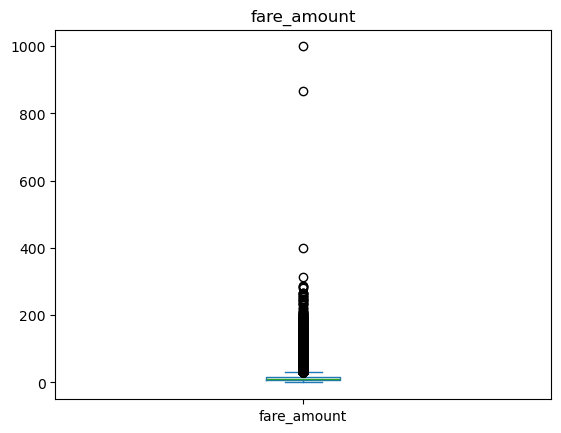

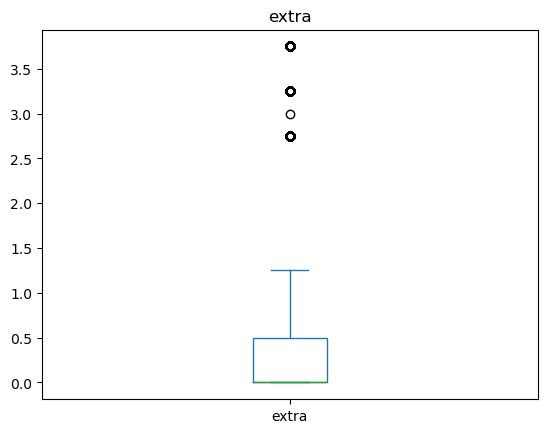

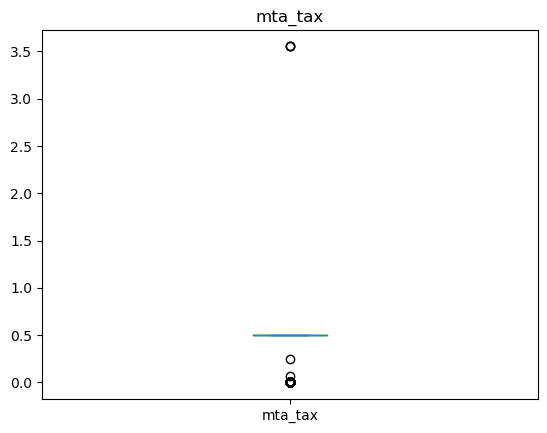

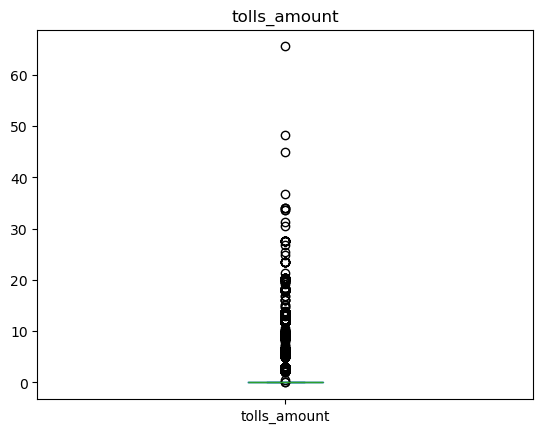

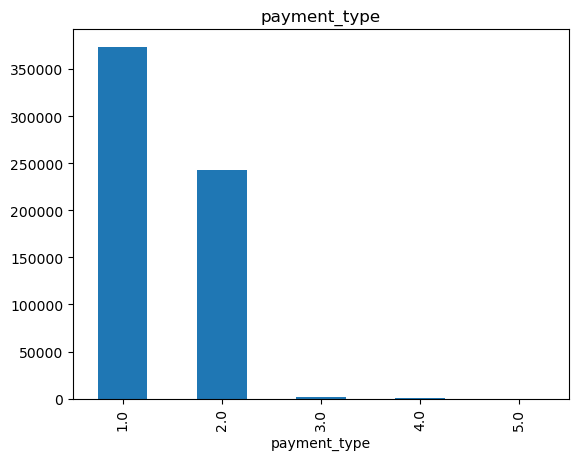

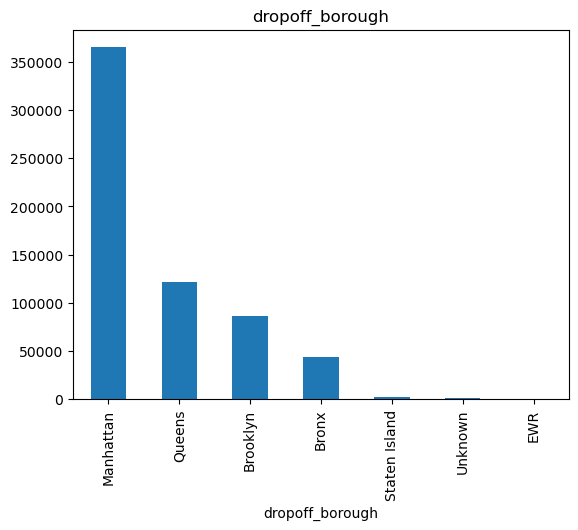

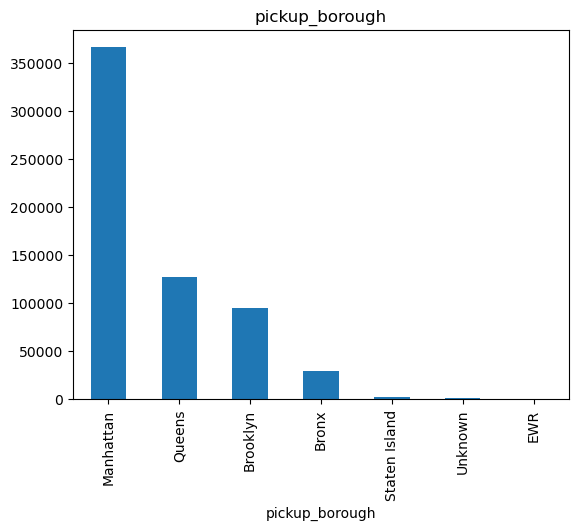

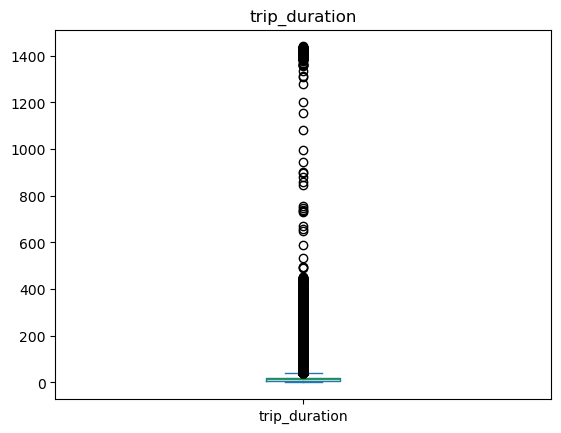

In [284]:
for col in df.columns:
    if df[col].dtype == 'double[pyarrow]' or df[col].dtype == 'float64':
        df[col].plot(kind='box')
    else:
        df[col].value_counts().plot(kind='bar')
        
    plt.title(col)
    plt.show()